In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import re
import neptune
import pingouin as pg

import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from scipy.stats import pearsonr

In [2]:
vi_datapath = "../data/responses/verbal intelligence analysis - HumanExpert1.csv"
vi_datapath_2 = "../data/responses/verbal intelligence analysis - HumanExpert2.csv"
vi_datapath_3 = "../data/responses/verbal intelligence analysis - HumanExpert3.csv"
vi_datapath_ai_ex = "../data/reporting/assesed_verbal_intelligence.csv"
vi_datapath_ai_norm = "../data/reporting/v_intel_assesed_normal.csv"
vi_datapath_ai_03 = "../data/reporting/v_intel_assesed_o3mini.csv"
vi_data = pd.read_csv(vi_datapath)
vi_data_2 = pd.read_csv(vi_datapath_2)
vi_data_3 = pd.read_csv(vi_datapath_3)
vi_data_ai_ex = pd.read_csv(vi_datapath_ai_ex)
vi_data_ai_norm = pd.read_csv(vi_datapath_ai_norm)
vi_data_ai_03 = pd.read_csv(vi_datapath_ai_03)

In [3]:
mapping = {
    "Prompt violating policy": np.nan,
    "Extremely high intelligence": 5,
    "High intelligence": 4,
    "Average intelligence": 3,
    "Low intelligence": 2,
    "Extremely low intelligence": 1
}
vi_data["assessment_numeric"] = vi_data["Assessment:"].map(mapping)
vi_data_2["assessment_numeric"] = vi_data_2["Assessment:"].map(mapping)
vi_data_3["assessment_numeric"] = vi_data_3["Assessment:"].map(mapping)
vi_data_ai_ex["assessment_numeric"] = vi_data_ai_ex["score"].map(mapping)
vi_data_ai_norm["assessment_numeric"] = vi_data_ai_norm["score"].map(mapping)
vi_data_ai_03["assessment_numeric"] = vi_data_ai_03["score"].map(mapping)
vi_data["assessment_numeric"] = vi_data["assessment_numeric"].astype(int)
vi_data_2["assessment_numeric"] = vi_data_2["assessment_numeric"].astype(int)
vi_data_3["assessment_numeric"] = vi_data_3["assessment_numeric"].astype(int)

In [4]:
vi_data["assessment_numeric"].mean(), vi_data["assessment_numeric"].std()

(3.1416666666666666, 0.6390096504226938)

In [5]:
vi_data_2["assessment_numeric"].mean(), vi_data_2["assessment_numeric"].std()

(3.25, 0.6642111641550714)

In [6]:
vi_data_3["assessment_numeric"].mean(), vi_data_3["assessment_numeric"].std()

(2.8666666666666667, 0.9608586262920721)

In [7]:
vi_data_ai_ex["assessment_numeric"].mean(), vi_data_ai_ex["assessment_numeric"].std()

(3.1565217391304348, 1.2396328286883425)

In [8]:
# rename the columns
vi_data_ai_ex = vi_data_ai_ex.rename(columns={"score": "Assessment:", 
                                        "assessment_numeric": "ai_assessment_ex",
                                        "reason": "reason_ex"})
vi_data_ai_norm = vi_data_ai_norm.rename(columns={"score": "Assessment:",
                                        "assessment_numeric": "ai_assessment_norm",
                                        "reason": "reason_norm"})
vi_data_ai_03 = vi_data_ai_03.rename(columns={"score": "Assessment:",
                                        "assessment_numeric": "ai_assessment_03",
                                        "reason": "reason_ai_03"})
vi_data = vi_data.rename(columns={"assessment_numeric": "human_assessment_1","Post:": "post"})
vi_data_2 = vi_data_2.rename(columns={"assessment_numeric": "human_assessment_2", "Post:": "post"})
vi_data_3 = vi_data_3.rename(columns={"assessment_numeric": "human_assessment_3", "Post:": "post"})

# Drop the assessment columns
vi_data = vi_data.drop(columns=["Assessment:"])
vi_data_2 = vi_data_2.drop(columns=["Assessment:"])
vi_data_3 = vi_data_3.drop(columns=["Assessment:"])
vi_data_ai_ex = vi_data_ai_ex.drop(columns=["Assessment:"])
vi_data_ai_norm = vi_data_ai_norm.drop(columns=["Assessment:"])
vi_data_ai_03 = vi_data_ai_03.drop(columns=["Assessment:"])


In [9]:
# join the dataframes
data = pd.merge(vi_data, vi_data_2, on="post", how="inner")
data = pd.merge(data, vi_data_3, on="post", how="inner")
data = pd.merge(data, vi_data_ai_ex, on="post", how="inner")
data = pd.merge(data, vi_data_ai_norm, on="post", how="inner")
data = pd.merge(data, vi_data_ai_03, on="post", how="inner")
# remove the columns that are not needed
# data = pd.concat([vi_data, vi_data_2, vi_data_3, vi_data_ai], axis=1 ).reset_index()
data["human_assessment"] = data[["human_assessment_1", "human_assessment_2", "human_assessment_3"]].mean(axis=1)
data["human_assessment_int"] = data["human_assessment"].astype(int)

In [10]:
data.head()

,post,human_assessment_1,human_assessment_2,human_assessment_3,reason_ex,ai_assessment_ex,reason_norm,ai_assessment_norm,reason_ai_03,ai_assessment_03,human_assessment,human_assessment_int
0,As you all know I don't like to travel. But I ...,3,3,3,"The text is clear and coherent, utilizing str...",3.0,The text exhibits a basic level of verbal int...,3.0,"The text demonstrates a typical, everyday use...",3.0,3.000000,3
1,I went to Dún Laoghaire and it was lovely,2,3,2,"The statement ""I went to Dún Laoghaire and it...",1.0,"The statement ""I went to Dún Laoghaire and it...",3.0,The sentence “I went to Dún Laoghaire and it ...,2.0,2.333333,2
2,Imagine strolling along the sandy shores of th...,4,4,4,The text exhibits a sophisticated use of lang...,4.0,The text exhibits a strong command of verbal ...,4.0,The text demonstrates a well-developed comman...,4.0,4.000000,4
3,just returned from an unforgettable trip to Ky...,4,4,3,The text showcases a strong command of langua...,4.0,The text exhibits a strong command of languag...,4.0,"The text uses a vivid, imaginative language t...",4.0,3.666667,3
4,"I traveled to Tokyo for leisure and fun, i boo...",2,3,2,The text employs basic language and simple se...,2.0,The text demonstrates a basic ability to conv...,3.0,"The text is written in a very simple, straigh...",2.0,2.333333,2


In [11]:
# drop the columns that have 0 in ai_assessment
data = data.dropna(subset=["ai_assessment_ex", "ai_assessment_norm", "ai_assessment_03"])

In [12]:
data.shape

(112, 12)

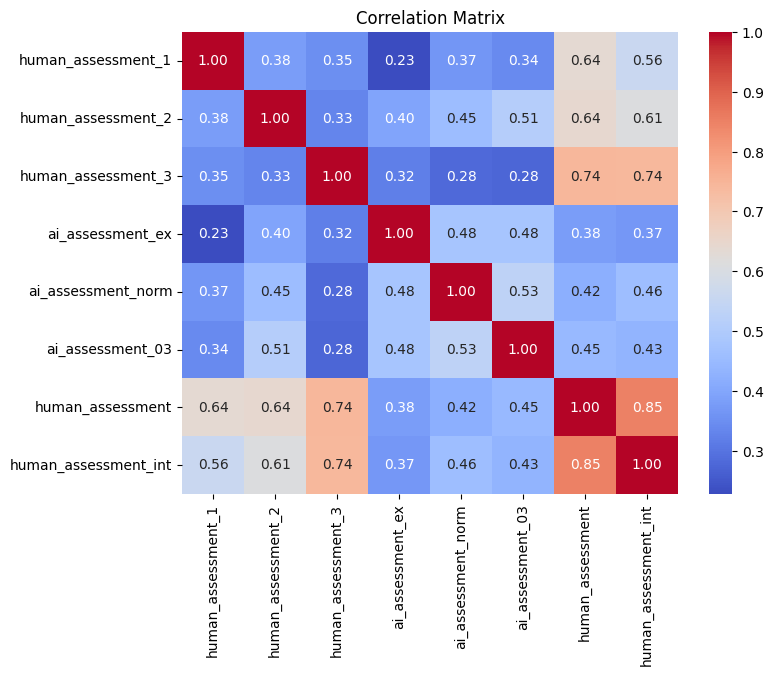

In [13]:
df_numeric = data.select_dtypes(include=["number"])

corr=df_numeric.corr(method="kendall")


plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Matrix")
plt.show()


# Procentages of responses

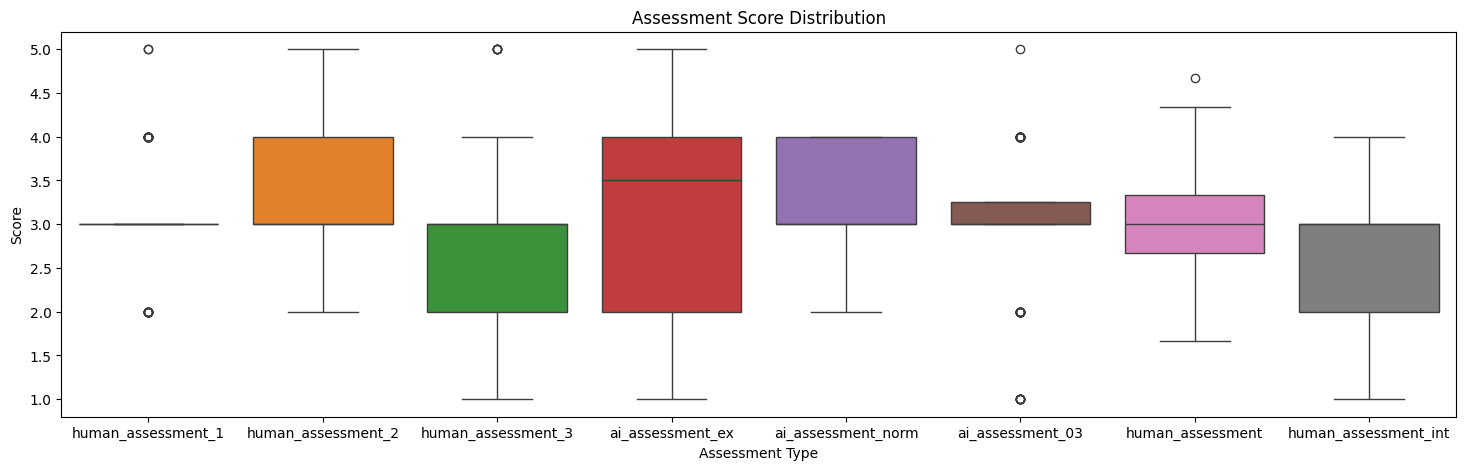

In [14]:
plt.figure(figsize=(18, 5))
sns.boxplot(data=df_numeric)
plt.title("Assessment Score Distribution")
plt.xlabel("Assessment Type")
plt.ylabel("Score")
plt.show()

# Comparison cd.

In [15]:
# Calculate Kendall’s W
# pg.pairwise_corr(data, method="kendall", columns=["human_assessment_1",
#                                                   "human_assessment_2",
#                                                   "human_assessment_3", 
#                                                   "ai_assessment_ex", 
#                                                   "ai_assessment_norm", 
#                                                   "ai_assessment_03"], 
#                                                   padjust="holm")

In [16]:
data.head()

,post,human_assessment_1,human_assessment_2,human_assessment_3,reason_ex,ai_assessment_ex,reason_norm,ai_assessment_norm,reason_ai_03,ai_assessment_03,human_assessment,human_assessment_int
0,As you all know I don't like to travel. But I ...,3,3,3,"The text is clear and coherent, utilizing str...",3.0,The text exhibits a basic level of verbal int...,3.0,"The text demonstrates a typical, everyday use...",3.0,3.000000,3
1,I went to Dún Laoghaire and it was lovely,2,3,2,"The statement ""I went to Dún Laoghaire and it...",1.0,"The statement ""I went to Dún Laoghaire and it...",3.0,The sentence “I went to Dún Laoghaire and it ...,2.0,2.333333,2
2,Imagine strolling along the sandy shores of th...,4,4,4,The text exhibits a sophisticated use of lang...,4.0,The text exhibits a strong command of verbal ...,4.0,The text demonstrates a well-developed comman...,4.0,4.000000,4
3,just returned from an unforgettable trip to Ky...,4,4,3,The text showcases a strong command of langua...,4.0,The text exhibits a strong command of languag...,4.0,"The text uses a vivid, imaginative language t...",4.0,3.666667,3
4,"I traveled to Tokyo for leisure and fun, i boo...",2,3,2,The text employs basic language and simple se...,2.0,The text demonstrates a basic ability to conv...,3.0,"The text is written in a very simple, straigh...",2.0,2.333333,2


In [17]:
# Change all raters [human_assessment_1, human_assessment_2, human_assessment_3] to one column
df_long = data.melt(
                  id_vars=['post'],        # columns to keep (not unpivot)
                  value_vars=["human_assessment_1", "human_assessment_2", "human_assessment_3"])

df_long_ai = data.melt(
                id_vars=['post'],        # columns to keep (not unpivot)
                value_vars=["human_assessment_1", "human_assessment_2", "human_assessment_3","ai_assessment_ex"])

df_long_ai_03 = data.melt(
                id_vars=['post'],        # columns to keep (not unpivot)
                value_vars=["human_assessment_1", "human_assessment_2", "human_assessment_3","ai_assessment_03"])

df_long_ai_norm = data.melt(
                id_vars=['post'],        # columns to keep (not unpivot)
                value_vars=["human_assessment_1", "human_assessment_2", "human_assessment_3","ai_assessment_norm"])


In [18]:
df_long.head()

,post,variable,value
0,As you all know I don't like to travel. But I ...,human_assessment_1,3
1,I went to Dún Laoghaire and it was lovely,human_assessment_1,2
2,Imagine strolling along the sandy shores of th...,human_assessment_1,4
3,just returned from an unforgettable trip to Ky...,human_assessment_1,4
4,"I traveled to Tokyo for leisure and fun, i boo...",human_assessment_1,2


In [19]:
# pg.friedman(data[["human_assessment_1","human_assessment_2", "human_assessment_3","ai_assessment"]])

In [20]:
# pg.friedman(data[["human_assessment_1","human_assessment_2", "human_assessment_3"]])

In [21]:
pg.intraclass_corr(df_long, targets="post", raters="variable", ratings="value")

,Type,Description,ICC,F,df1,df2,pval,CI95%
0,ICC1,Single raters absolute,0.322198,2.426073,111,224,1.067322e-08,"[0.2, 0.44]"
1,ICC2,Single random raters,0.334509,2.642424,111,222,4.248326e-10,"[0.22, 0.45]"
2,ICC3,Single fixed raters,0.353786,2.642424,111,222,4.248326e-10,"[0.24, 0.47]"
3,ICC1k,Average raters absolute,0.587811,2.426073,111,224,1.067322e-08,"[0.44, 0.7]"
4,ICC2k,Average random raters,0.601268,2.642424,111,222,4.248326e-10,"[0.45, 0.71]"
5,ICC3k,Average fixed raters,0.621560,2.642424,111,222,4.248326e-10,"[0.48, 0.73]"


In [22]:
pg.intraclass_corr(df_long_ai, targets="post", raters="variable", ratings="value").round(4)

,Type,Description,ICC,F,df1,df2,pval,CI95%
0,ICC1,Single raters absolute,0.3136,2.8275,111,336,0.0,"[0.22, 0.42]"
1,ICC2,Single random raters,0.3178,2.9340,111,333,0.0,"[0.22, 0.42]"
2,ICC3,Single fixed raters,0.3259,2.9340,111,333,0.0,"[0.23, 0.43]"
3,ICC1k,Average raters absolute,0.6463,2.8275,111,336,0.0,"[0.53, 0.74]"
4,ICC2k,Average random raters,0.6508,2.9340,111,333,0.0,"[0.53, 0.75]"
5,ICC3k,Average fixed raters,0.6592,2.9340,111,333,0.0,"[0.54, 0.75]"


In [23]:
pg.intraclass_corr(df_long_ai_03, targets="post", raters="variable", ratings="value").round(4)

,Type,Description,ICC,F,df1,df2,pval,CI95%
0,ICC1,Single raters absolute,0.3442,3.0997,111,336,0.0,"[0.25, 0.45]"
1,ICC2,Single random raters,0.3507,3.2998,111,333,0.0,"[0.25, 0.45]"
2,ICC3,Single fixed raters,0.3651,3.2998,111,333,0.0,"[0.27, 0.47]"
3,ICC1k,Average raters absolute,0.6774,3.0997,111,336,0.0,"[0.57, 0.76]"
4,ICC2k,Average random raters,0.6836,3.2998,111,333,0.0,"[0.58, 0.77]"
5,ICC3k,Average fixed raters,0.6970,3.2998,111,333,0.0,"[0.59, 0.78]"


In [24]:
pg.intraclass_corr(df_long_ai_norm, targets="post", raters="variable", ratings="value").round(4)

,Type,Description,ICC,F,df1,df2,pval,CI95%
0,ICC1,Single raters absolute,0.3080,2.7803,111,336,0.0,"[0.21, 0.41]"
1,ICC2,Single random raters,0.3211,3.1304,111,333,0.0,"[0.22, 0.43]"
2,ICC3,Single fixed raters,0.3475,3.1304,111,333,0.0,"[0.25, 0.45]"
3,ICC1k,Average raters absolute,0.6403,2.7803,111,336,0.0,"[0.52, 0.74]"
4,ICC2k,Average random raters,0.6542,3.1304,111,333,0.0,"[0.53, 0.75]"
5,ICC3k,Average fixed raters,0.6806,3.1304,111,333,0.0,"[0.57, 0.77]"


Intraclass correlation interesting for us (ICC3 - Two-way mixed: k fixed raters are defined. Each subject is measured by the k raters. and Single measures: even though more than one measure is taken in the experiment, reliability is applied to a context where a single measure of a single rater will be performed;)

ICC = 0.3214

# Consistensy of AI posts

In [25]:
vi_datapath_ai = "../data/reporting/assesed_verbal_intelligence.csv"
vi_datapath_ai_2 = "../data/reporting/v_intel_assesed_ex_2.csv"
vi_datapath_ai_3 = "../data/reporting/v_intel_assesed_ex_3.csv"
vi_datapath_ai_norm = "../data/reporting/v_intel_assesed_normal.csv"
vi_data_ai = pd.read_csv(vi_datapath_ai)
vi_data_ai_2 = pd.read_csv(vi_datapath_ai_2)
vi_data_ai_3 = pd.read_csv(vi_datapath_ai_3)
vi_data_ai_norm = pd.read_csv(vi_datapath_ai_norm)

In [26]:
mapping = {
    "Prompt violating policy": np.nan,
    "Extremely high intelligence": 5,
    "High intelligence": 4,
    "Average intelligence": 3,
    "Low intelligence": 2,
    "Extremely low intelligence": 1
}
vi_data_ai["assessment_numeric"] = vi_data_ai["score"].map(mapping)
vi_data_ai_2["assessment_numeric"] = vi_data_ai_2["score"].map(mapping)
vi_data_ai_3["assessment_numeric"] = vi_data_ai_3["score"].map(mapping)
vi_data_ai_norm["assessment_numeric"] = vi_data_ai_norm["score"].map(mapping)

In [27]:
vi_data_ai = vi_data_ai.rename(columns={"score": "Assessment:", 
                                        "assessment_numeric": "ai_assessment_1"})
vi_data_ai_2 = vi_data_ai_2.rename(columns={"score": "Assessment:",
                                        "assessment_numeric": "ai_assessment_2"})
vi_data_ai_3 = vi_data_ai_3.rename(columns={"score": "Assessment:",
                                        "assessment_numeric": "ai_assessment_3"})
vi_data_ai_norm = vi_data_ai_norm.rename(columns={"score": "Assessment:",
                                        "assessment_numeric": "ai_assessment_normal"})

vi_data_ai = vi_data_ai.drop(columns=["Assessment:", "reason"])
vi_data_ai_2 = vi_data_ai_2.drop(columns=["Assessment:", "reason"])
vi_data_ai_3 = vi_data_ai_3.drop(columns=["Assessment:", "reason"])
vi_data_ai_norm = vi_data_ai_norm.drop(columns=["Assessment:", "reason"])

In [28]:
data_ai = pd.merge(vi_data_ai, vi_data_ai_2, on="post", how="inner")
data_ai = pd.merge(data_ai, vi_data_ai_3, on="post", how="inner")
data_ai = pd.merge(data_ai, vi_data_ai_norm, on="post", how="inner")

In [29]:
# drop the columns that have 0 in ai_assessment
data_ai = data_ai.dropna()
data_ai.shape

(103, 5)

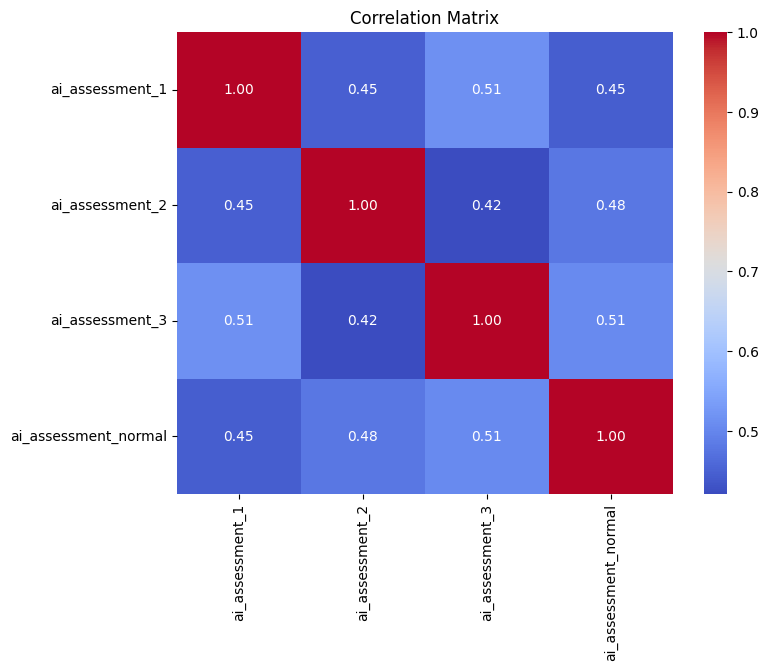

In [30]:
df_numeric = data_ai.select_dtypes(include=["number"])

corr=df_numeric.corr(method="kendall")


plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Matrix")
plt.show()

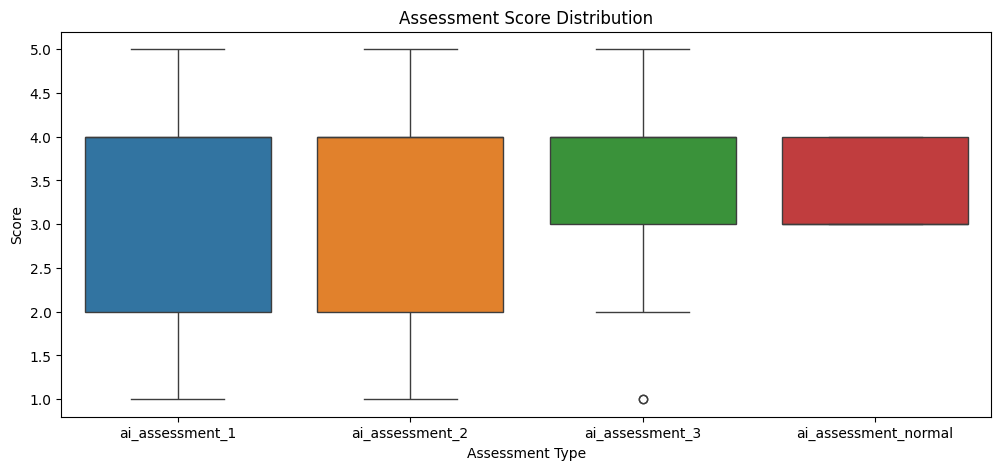

In [31]:
plt.figure(figsize=(12, 5))
sns.boxplot(data=df_numeric)
plt.title("Assessment Score Distribution")
plt.xlabel("Assessment Type")
plt.ylabel("Score")
plt.show()

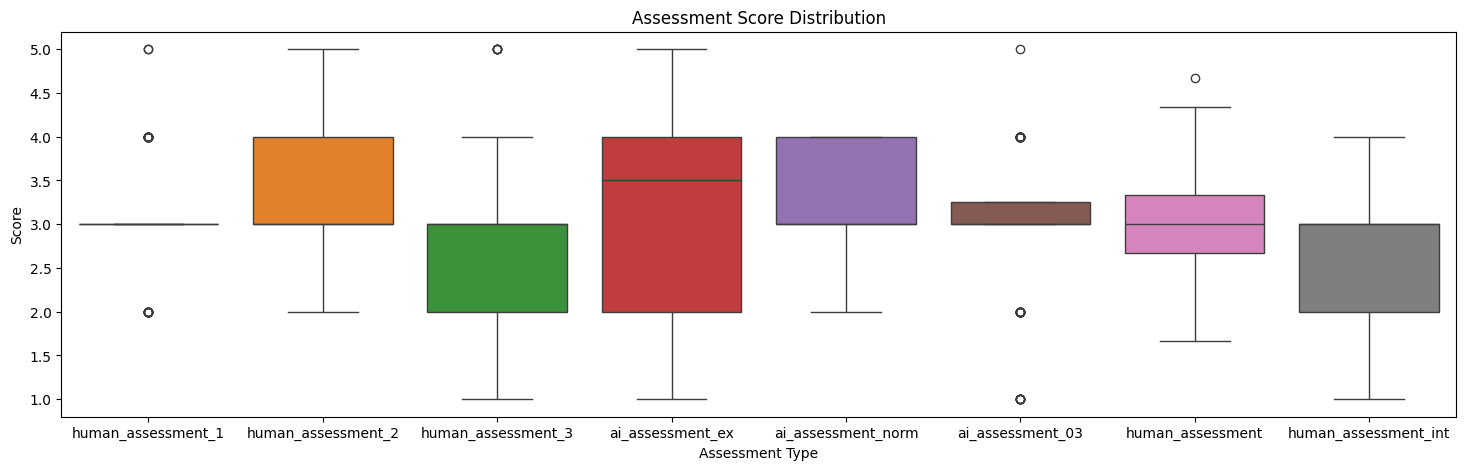

In [32]:
df_numeric = data.select_dtypes(include=["number"])

plt.figure(figsize=(18, 5))
sns.boxplot(data=df_numeric)
plt.title("Assessment Score Distribution")
plt.xlabel("Assessment Type")
plt.ylabel("Score")
plt.show()

In [33]:
# Change all raters [human_assessment_1, human_assessment_2, human_assessment_3] to one column
df_long_only_ai = data_ai.melt(
                  id_vars=['post'],        # columns to keep (not unpivot)
                  value_vars=["ai_assessment_1", "ai_assessment_2", "ai_assessment_3"])

df_long_only_ai_norm = data_ai.melt(
                id_vars=['post'],        # columns to keep (not unpivot)
                value_vars=["ai_assessment_1", "ai_assessment_2", "ai_assessment_3","ai_assessment_normal"])

In [34]:
data_ai.shape

(103, 5)

In [35]:
pg.intraclass_corr(df_long_only_ai, targets="post", raters="variable", ratings="value", nan_policy="omit")

,Type,Description,ICC,F,df1,df2,pval,CI95%
0,ICC1,Single raters absolute,0.506037,4.073333,102,206,6.339991e-18,"[0.39, 0.61]"
1,ICC2,Single random raters,0.508540,4.203349,102,204,1.480142e-18,"[0.39, 0.62]"
2,ICC3,Single fixed raters,0.516390,4.203349,102,204,1.480142e-18,"[0.4, 0.62]"
3,ICC1k,Average raters absolute,0.754501,4.073333,102,206,6.339991e-18,"[0.66, 0.83]"
4,ICC2k,Average random raters,0.756351,4.203349,102,204,1.480142e-18,"[0.66, 0.83]"
5,ICC3k,Average fixed raters,0.762094,4.203349,102,204,1.480142e-18,"[0.67, 0.83]"


In [36]:
pg.intraclass_corr(df_long_only_ai_norm, targets="post", raters="variable", ratings="value", nan_policy="omit")

,Type,Description,ICC,F,df1,df2,pval,CI95%
0,ICC1,Single raters absolute,0.454761,4.33623,102,309,1.587915e-23,"[0.35, 0.56]"
1,ICC2,Single random raters,0.456519,4.44163,102,306,3.648700e-24,"[0.36, 0.56]"
2,ICC3,Single fixed raters,0.462483,4.44163,102,306,3.648700e-24,"[0.36, 0.56]"
3,ICC1k,Average raters absolute,0.769385,4.33623,102,309,1.587915e-23,"[0.69, 0.83]"
4,ICC2k,Average random raters,0.770640,4.44163,102,306,3.648700e-24,"[0.69, 0.84]"
5,ICC3k,Average fixed raters,0.774857,4.44163,102,306,3.648700e-24,"[0.69, 0.84]"


In [37]:
### Kendall's W
#### Has no sense in this case, because we don't rank

# ranked_df = data[['human_assessment_1', 'human_assessment_2', 'human_assessment_3', 'ai_assessment']].apply(
#     lambda x: x.rank(), axis=1)
# # Step 2: Compute the mean rank for each post

# sum_of_ranks = ranked_df.sum(axis=1)

# mean_rank = ranked_df.mean(axis=1)

# # Step 3: Calculate S (sum of squared deviations from the mean rank)
# S = np.sum((sum_of_ranks - mean_rank) ** 2)

# # Step 4: Calculate Kendall’s W
# n = len(data)  # Number of items (posts)  
# k = len(ranked_df.columns)

# W = (12 * S) / (k * (n**3 - n))

# print(f"Kendall's W: {W:.4f}")

# Check if there is a by post connection

In [38]:
# load verbal intelligence temp
vi_datapath_temp = "../data/reporting/verbal_intelligence_temp.csv"
vi_data_temp = pd.read_csv(vi_datapath_temp)
data.rename(columns={"Post:": "post"}, inplace=True)

In [39]:
# add topic to the data
data = pd.merge(data, vi_data_temp, on="post", how="inner")

In [40]:
data.head()

,post,human_assessment_1,human_assessment_2,human_assessment_3,reason_ex,ai_assessment_ex,reason_norm,ai_assessment_norm,reason_ai_03,ai_assessment_03,human_assessment,human_assessment_int,adm,riv,post_type
0,As you all know I don't like to travel. But I ...,3,3,3,"The text is clear and coherent, utilizing str...",3.0,The text exhibits a basic level of verbal int...,3.0,"The text demonstrates a typical, everyday use...",3.0,3.000000,3,2.222,2.111,post_travel
1,I went to Dún Laoghaire and it was lovely,2,3,2,"The statement ""I went to Dún Laoghaire and it...",1.0,"The statement ""I went to Dún Laoghaire and it...",3.0,The sentence “I went to Dún Laoghaire and it ...,2.0,2.333333,2,3.111,2.333,post_travel
2,Imagine strolling along the sandy shores of th...,4,4,4,The text exhibits a sophisticated use of lang...,4.0,The text exhibits a strong command of verbal ...,4.0,The text demonstrates a well-developed comman...,4.0,4.000000,4,5.222,2.111,post_travel
3,just returned from an unforgettable trip to Ky...,4,4,3,The text showcases a strong command of langua...,4.0,The text exhibits a strong command of languag...,4.0,"The text uses a vivid, imaginative language t...",4.0,3.666667,3,4.444,3.667,post_travel
4,"I traveled to Tokyo for leisure and fun, i boo...",2,3,2,The text employs basic language and simple se...,2.0,The text demonstrates a basic ability to conv...,3.0,"The text is written in a very simple, straigh...",2.0,2.333333,2,3.778,2.000,post_travel


In [41]:
data_travel = data[data["post_type"] == "post_travel"]

df_long_tr = data_travel.melt(
                  id_vars=['post'],        # columns to keep (not unpivot)
                  value_vars=["human_assessment_1", "human_assessment_2", "human_assessment_3"])

pg.intraclass_corr(df_long_tr, targets="post", raters="variable", ratings="value")

,Type,Description,ICC,F,df1,df2,pval,CI95%
0,ICC1,Single raters absolute,0.364832,2.723158,38,78,0.000093,"[0.17, 0.56]"
1,ICC2,Single random raters,0.378272,3.032825,38,76,0.000019,"[0.19, 0.57]"
2,ICC3,Single fixed raters,0.403913,3.032825,38,76,0.000019,"[0.21, 0.6]"
3,ICC1k,Average raters absolute,0.632779,2.723158,38,78,0.000093,"[0.38, 0.79]"
4,ICC2k,Average random raters,0.646051,3.032825,38,76,0.000019,"[0.41, 0.8]"
5,ICC3k,Average fixed raters,0.670274,3.032825,38,76,0.000019,"[0.44, 0.82]"


In [42]:
df_long_tr_ai = data_travel.melt(
                  id_vars=['post'],        # columns to keep (not unpivot)
                  value_vars=["human_assessment_1", "human_assessment_2", "human_assessment_3", "ai_assessment_norm"])

pg.intraclass_corr(df_long_tr_ai, targets="post", raters="variable", ratings="value")

,Type,Description,ICC,F,df1,df2,pval,CI95%
0,ICC1,Single raters absolute,0.364207,3.291353,38,117,4.592491e-07,"[0.2, 0.54]"
1,ICC2,Single random raters,0.372765,3.600411,38,114,7.069479e-08,"[0.21, 0.55]"
2,ICC3,Single fixed raters,0.393977,3.600411,38,114,7.069479e-08,"[0.23, 0.57]"
3,ICC1k,Average raters absolute,0.696174,3.291353,38,117,4.592491e-07,"[0.5, 0.83]"
4,ICC2k,Average random raters,0.703896,3.600411,38,114,7.069479e-08,"[0.52, 0.83]"
5,ICC3k,Average fixed raters,0.722254,3.600411,38,114,7.069479e-08,"[0.55, 0.84]"


In [43]:
data_abortion = data[data["post_type"] == "post_abortion"]

df_long_ab = data_abortion.melt(
                    id_vars=['post'],        # columns to keep (not unpivot)
                    value_vars=["human_assessment_1", "human_assessment_2", "human_assessment_3"])
pg.intraclass_corr(df_long_ab, targets="post", raters="variable", ratings="value")

,Type,Description,ICC,F,df1,df2,pval,CI95%
0,ICC1,Single raters absolute,0.426618,3.232114,34,70,0.000017,"[0.22, 0.62]"
1,ICC2,Single random raters,0.425046,3.186520,34,68,0.000024,"[0.22, 0.62]"
2,ICC3,Single fixed raters,0.421578,3.186520,34,68,0.000024,"[0.21, 0.62]"
3,ICC1k,Average raters absolute,0.690605,3.232114,34,70,0.000017,"[0.46, 0.83]"
4,ICC2k,Average random raters,0.689229,3.186520,34,68,0.000024,"[0.45, 0.83]"
5,ICC3k,Average fixed raters,0.686178,3.186520,34,68,0.000024,"[0.45, 0.83]"


In [44]:
df_long_ab_ai = data_abortion.melt(
                    id_vars=['post'],        # columns to keep (not unpivot)
                    value_vars=["human_assessment_1", "human_assessment_2", "human_assessment_3", "ai_assessment_norm"])
pg.intraclass_corr(df_long_ab_ai, targets="post", raters="variable", ratings="value")

,Type,Description,ICC,F,df1,df2,pval,CI95%
0,ICC1,Single raters absolute,0.389985,3.557212,34,105,3.435537e-07,"[0.22, 0.58]"
1,ICC2,Single random raters,0.395371,3.777920,34,102,1.134351e-07,"[0.23, 0.58]"
2,ICC3,Single fixed raters,0.409848,3.777920,34,102,1.134351e-07,"[0.24, 0.59]"
3,ICC1k,Average raters absolute,0.718881,3.557212,34,105,3.435537e-07,"[0.53, 0.84]"
4,ICC2k,Average random raters,0.723423,3.777920,34,102,1.134351e-07,"[0.54, 0.85]"
5,ICC3k,Average fixed raters,0.735304,3.777920,34,102,1.134351e-07,"[0.56, 0.85]"


In [45]:
data_ai = data[data["post_type"] == "post_ai"]

df_long_ai = data_ai.melt(
                    id_vars=['post'],        # columns to keep (not unpivot)
                    value_vars=["human_assessment_1", "human_assessment_2", "human_assessment_3"])
pg.intraclass_corr(df_long_ai, targets="post", raters="variable", ratings="value")

,Type,Description,ICC,F,df1,df2,pval,CI95%
0,ICC1,Single raters absolute,0.173279,1.628792,37,76,0.036999,"[-0.02, 0.39]"
1,ICC2,Single random raters,0.203777,1.891736,37,74,0.010094,"[0.03, 0.41]"
2,ICC3,Single fixed raters,0.229136,1.891736,37,74,0.010094,"[0.03, 0.45]"
3,ICC1k,Average raters absolute,0.386048,1.628792,37,76,0.036999,"[-0.05, 0.66]"
4,ICC2k,Average random raters,0.434321,1.891736,37,74,0.010094,"[0.08, 0.68]"
5,ICC3k,Average fixed raters,0.471385,1.891736,37,74,0.010094,"[0.09, 0.71]"


In [46]:
df_long_ai_ai = data_ai.melt(
                    id_vars=['post'],        # columns to keep (not unpivot)
                    value_vars=["human_assessment_1", "human_assessment_2", "human_assessment_3","ai_assessment_norm"])
pg.intraclass_corr(df_long_ai_ai, targets="post", raters="variable", ratings="value")

,Type,Description,ICC,F,df1,df2,pval,CI95%
0,ICC1,Single raters absolute,0.171439,1.827647,37,114,0.008272,"[0.03, 0.36]"
1,ICC2,Single random raters,0.204441,2.285319,37,111,0.000489,"[0.07, 0.38]"
2,ICC3,Single fixed raters,0.243187,2.285319,37,111,0.000489,"[0.09, 0.43]"
3,ICC1k,Average raters absolute,0.452848,1.827647,37,114,0.008272,"[0.1, 0.69]"
4,ICC2k,Average random raters,0.506882,2.285319,37,111,0.000489,"[0.22, 0.71]"
5,ICC3k,Average fixed raters,0.562424,2.285319,37,111,0.000489,"[0.28, 0.75]"


## Compare three psychologist (o4-mini)

In [48]:
em_int_psych1 = "../data/reporting/model_as_psych_test/v_intel_o4mini_Ania.csv"
em_int_psych2 = "../data/reporting/model_as_psych_test/v_intel_o4mini_Maria.csv"
em_int_psych3 = "../data/reporting/model_as_psych_test/v_intel_o4mini_Marysia.csv"

em_int_psych1_data = pd.read_csv(em_int_psych1)
em_int_psych2_data = pd.read_csv(em_int_psych2)
em_int_psych3_data = pd.read_csv(em_int_psych3)
mapping = {
    "Prompt violating policy": np.nan,
    "Extremely high intelligence": 5,
    "High intelligence": 4,
    "Average intelligence": 3,
    "Low intelligence": 2,
    "Extremely low intelligence": 1
}

In [49]:
em_int_psych1_data["assessment_numeric"] = em_int_psych1_data["score"].map(mapping)
em_int_psych2_data["assessment_numeric"] = em_int_psych2_data["score"].map(mapping)
em_int_psych3_data["assessment_numeric"] = em_int_psych3_data["score"].map(mapping)

In [50]:
em_int_psych1_data = em_int_psych1_data.rename(columns={"score": "Assessment:", 
                                        "assessment_numeric": "aih_assessment_1"})
em_int_psych2_data = em_int_psych2_data.rename(columns={"score": "Assessment:",
                                        "assessment_numeric": "aih_assessment_2"})
em_int_psych3_data = em_int_psych3_data.rename(columns={"score": "Assessment:",
                                        "assessment_numeric": "aih_assessment_3"})

em_int_psych1_data = em_int_psych1_data.drop(columns=["Assessment:", "reason"])
em_int_psych2_data = em_int_psych2_data.drop(columns=["Assessment:", "reason"])
em_int_psych3_data = em_int_psych3_data.drop(columns=["Assessment:", "reason"])


In [51]:
data_ai_3psych = pd.merge(em_int_psych1_data, em_int_psych2_data, on="post", how="inner")
data_ai_3psych = pd.merge(data_ai_3psych, em_int_psych3_data, on="post", how="inner")

In [52]:
data_ai_3psych = data_ai_3psych.dropna()
data_ai_3psych.shape

(119, 4)

In [53]:
df_long_ai_3psych = data_ai_3psych.melt(
                  id_vars=['post'],        # columns to keep (not unpivot)
                  value_vars=["aih_assessment_1", "aih_assessment_2", "aih_assessment_3"])

In [54]:
pg.intraclass_corr(df_long_ai_3psych, targets="post", raters="variable", ratings="value").round(4)

,Type,Description,ICC,F,df1,df2,pval,CI95%
0,ICC1,Single raters absolute,0.6007,5.5139,118,238,0.0,"[0.51, 0.69]"
1,ICC2,Single random raters,0.6005,5.4857,118,236,0.0,"[0.5, 0.69]"
2,ICC3,Single fixed raters,0.5992,5.4857,118,236,0.0,"[0.5, 0.69]"
3,ICC1k,Average raters absolute,0.8186,5.5139,118,238,0.0,"[0.75, 0.87]"
4,ICC2k,Average random raters,0.8185,5.4857,118,236,0.0,"[0.75, 0.87]"
5,ICC3k,Average fixed raters,0.8177,5.4857,118,236,0.0,"[0.75, 0.87]"


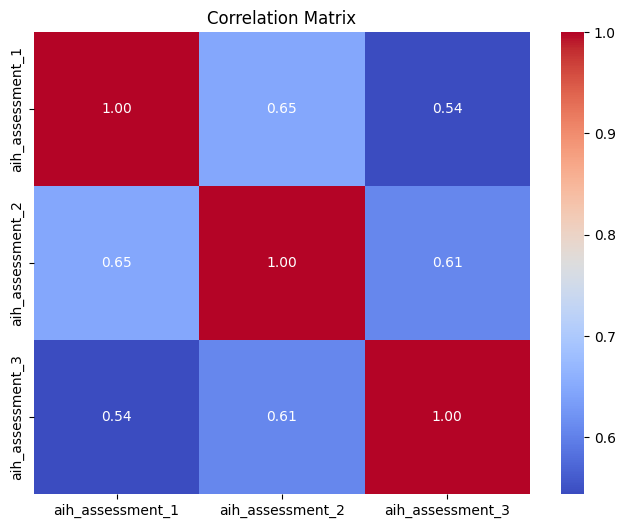

In [55]:
df_numeric_3psych = data_ai_3psych.select_dtypes(include=["number"])

corr=df_numeric_3psych.corr(method="pearson")


plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Matrix")
plt.show()


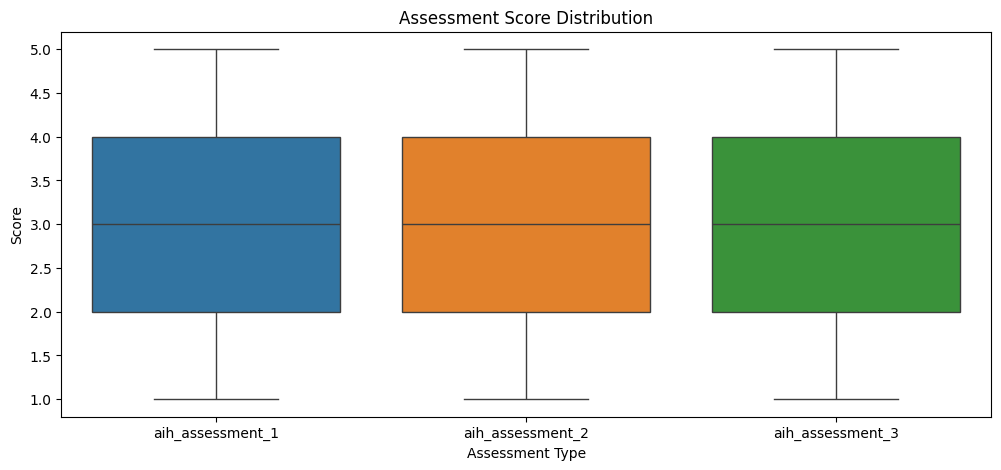

In [56]:
df_numeric_3psych = data_ai_3psych.select_dtypes(include=["number"])

plt.figure(figsize=(12, 5))
sns.boxplot(data=df_numeric_3psych)
plt.title("Assessment Score Distribution")
plt.xlabel("Assessment Type")
plt.ylabel("Score")
plt.show()

In [57]:
data_ai_3psych_comp = pd.merge(data_ai_3psych, vi_data, on ="post", how="inner")
data_ai_3psych_comp = pd.merge(data_ai_3psych_comp, vi_data_2, on ="post", how="inner")
data_ai_3psych_comp = pd.merge(data_ai_3psych_comp, vi_data_3, on ="post", how="inner")
data_ai_3psych_comp.head()

,post,aih_assessment_1,aih_assessment_2,aih_assessment_3,human_assessment_1,human_assessment_2,human_assessment_3
0,As you all know I don't like to travel. But I ...,3.0,2.0,3.0,3,3,3
1,I went to Dún Laoghaire and it was lovely,2.0,2.0,2.0,2,3,2
2,Imagine strolling along the sandy shores of th...,4.0,4.0,3.0,4,4,4
3,just returned from an unforgettable trip to Ky...,4.0,4.0,4.0,4,4,3
4,"I traveled to Tokyo for leisure and fun, i boo...",1.0,2.0,2.0,2,3,2


In [58]:
data_ai_3psych_comp["human_assessment_mean"] = data_ai_3psych_comp[["human_assessment_1", "human_assessment_2", "human_assessment_3"]].mean(axis=1)
data_ai_3psych_comp["aih_assessment_mean"] = data_ai_3psych_comp[["aih_assessment_1", "aih_assessment_2", "aih_assessment_3"]].mean(axis=1)



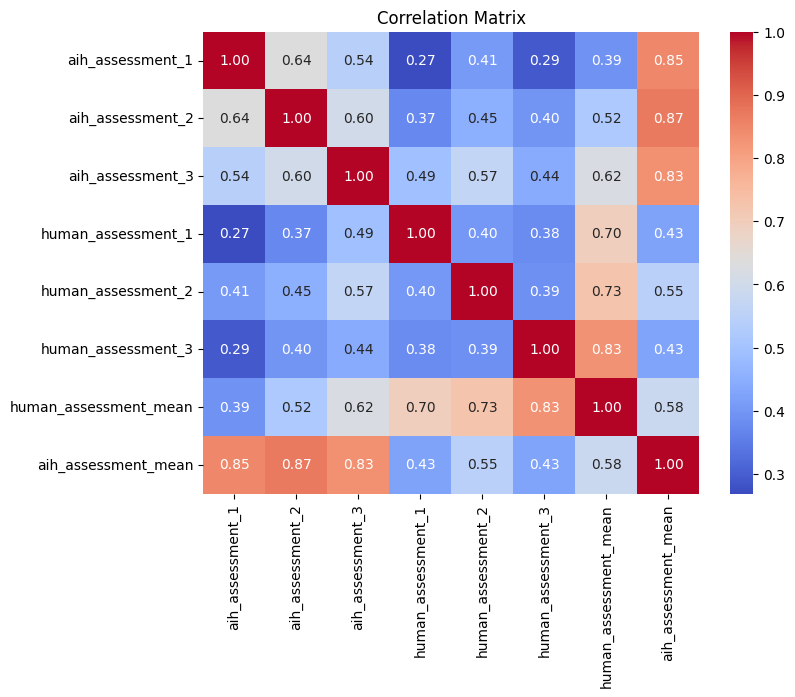

In [60]:
df_numeric_3psych_comp = data_ai_3psych_comp.select_dtypes(include=["number"])

corr=df_numeric_3psych_comp.corr(method="spearman")


plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Matrix")
plt.show()
